[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/02_probability_statistics.ipynb)

# 02 · Probability & Statistics for Machine Learning

**Part 0 — Foundations** · Notebook 2 of 27

Real data is noisy, and ML models are uncertain. Probability is the language for both. This notebook has one big destination: by the end you'll see that **loss functions are not arbitrary choices**. Mean squared error, cross-entropy and even L2 regularization all *fall out* of writing down a probability model and asking "which parameters make the data most likely?"

**What you'll learn**

1. Random variables and discrete distributions (and the law of large numbers)
2. Continuous distributions: densities vs. probabilities
3. Expectation and variance
4. The central limit theorem: why Gaussians are everywhere
5. Joint, marginal and conditional distributions; independence
6. Bayes' rule (and why a 99%-accurate test can still be wrong most of the time)
7. The multivariate Gaussian and covariance matrices
8. Maximum likelihood estimation (MLE)
9. Maximum a posteriori (MAP) estimation and priors
10. **From likelihoods to loss functions**: MSE, cross-entropy, MAE
11. Entropy, cross-entropy and KL divergence

*Course map: CX 4240 Lecture 3 (Probability & Statistics Revisit), Lectures 4 and 6 (Gaussian likelihood → least squares); Bishop, PRML Chapter 2.*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from scipy import stats

Setup complete ✓


---
## 1. Why ML needs probability

Three reasons, each of which this notebook makes concrete:

1. **Data is noisy.** Two apartments with the same size rent for different prices. We model the unexplained part as a *random variable*.
2. **Predictions should carry uncertainty.** "This email is spam with probability 0.93" is more useful than "spam".
3. **It tells us what to optimize.** Writing a probability model and maximizing the likelihood *gives you* the loss function. This is CX 4240's step 2: "derive the loss by MLE or MAP".

---
## 2. Random variables and discrete distributions

A **random variable** $X$ is a quantity whose value is determined by chance. A **discrete** one takes countable values, and is described by its **probability mass function (PMF)** $p(x) = P(X = x)$, with $\sum_x p(x) = 1$.

The three discrete distributions you'll use most:

| Distribution | Models | PMF | Used in |
|---|---|---|---|
| **Bernoulli**$(\phi)$ | one yes/no event | $\phi^x(1-\phi)^{1-x}$, $x\in\{0,1\}$ | binary classification (logistic regression) |
| **Binomial**$(n, \phi)$ | # of successes in $n$ trials | $\binom{n}{k}\phi^k(1-\phi)^{n-k}$ | counting |
| **Categorical**$(\pi_1..\pi_K)$ | one of $K$ outcomes | $\pi_k$ | multiclass classification, next-token prediction in GPT |

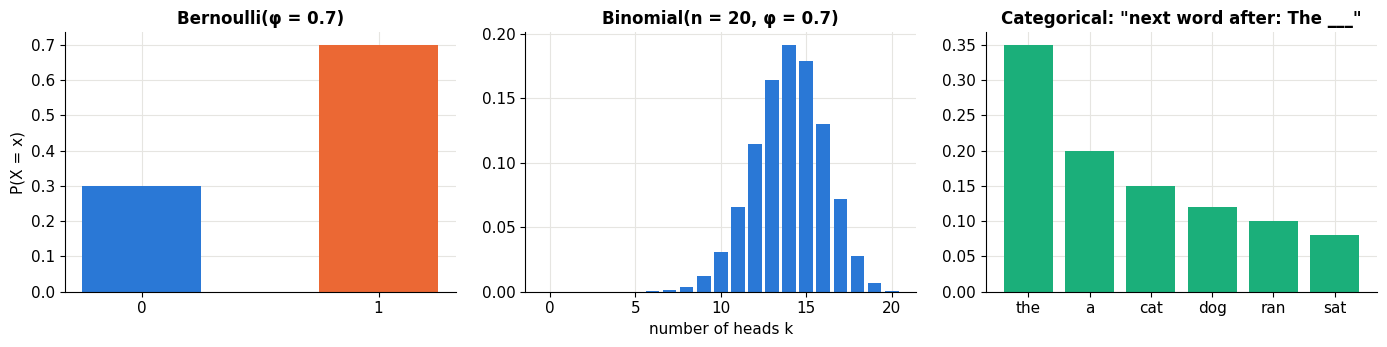

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].bar([0, 1], [0.3, 0.7], color=[C["blue"], C["orange"]], width=0.5)
axes[0].set(xticks=[0, 1], title="Bernoulli(φ = 0.7)", ylabel="P(X = x)")
k = np.arange(0, 21)
axes[1].bar(k, stats.binom.pmf(k, 20, 0.7), color=C["blue"])
axes[1].set(title="Binomial(n = 20, φ = 0.7)", xlabel="number of heads k")
words = ["the", "a", "cat", "dog", "ran", "sat"]
axes[2].bar(words, [0.35, 0.2, 0.15, 0.12, 0.1, 0.08], color=C["aqua"])
axes[2].set(title='Categorical: "next word after: The ___"')
fig.tight_layout(); plt.show()

### 🎬 The law of large numbers

Flip a biased coin ($\phi = 0.7$) over and over and track the **fraction of heads so far**. Each colored line is a separate experiment. Early on they're all over the place; as flips accumulate they all squeeze toward the true value 0.7. This is the **law of large numbers**: sample averages converge to the true expectation. It's why more data gives better estimates.

In [3]:
flips = rng.random((5, 500)) < 0.7
running = np.cumsum(flips, axis=1) / np.arange(1, 501)

fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
lines = [ax.plot([], [], lw=1.6)[0] for _ in range(5)]
ax.axhline(0.7, color=C["ink"], ls="--", lw=1.2, label="true φ = 0.7")
ax.set(xlim=(1, 500), ylim=(0, 1), xscale="log", xlabel="number of flips (log scale)",
       ylabel="fraction of heads so far", title="Law of large numbers")
ax.legend(loc="lower right")
fig.tight_layout()

def frame(f):
    upto = int(np.ceil(500 ** (f / 49)))           # grow on a log scale so early flips are visible
    for i, ln in enumerate(lines):
        ln.set_data(np.arange(1, upto + 1), running[i, :upto])
    return lines

show_anim(animation.FuncAnimation(fig, frame, frames=50, interval=90))

🎚️ **Binomial explorer.** Bars: the exact PMF. Dots: the result of actually simulating 2,000 experiments of $n$ flips each. Notice the shape becomes bell-like as $n$ grows. That's a sneak peek of the central limit theorem (section 5).

In [4]:
def plot_binom(n=10, phi=0.5):
    k = np.arange(0, n + 1)
    sims = rng.binomial(n, phi, size=2000)
    emp = np.bincount(sims, minlength=n + 1) / 2000
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.bar(k, stats.binom.pmf(k, n, phi), color=C["blue"], alpha=0.75, label="exact PMF")
    ax.plot(k, emp, "o", color=C["orange"], label="2,000 simulations")
    ax.set(xlabel="k (number of successes)", ylabel="probability",
           title=f"Binomial(n={n}, φ={phi:.2f}):  mean = nφ = {n*phi:.1f},  var = nφ(1−φ) = {n*phi*(1-phi):.2f}")
    ax.legend(); plt.show()

interact(plot_binom, n=IntSlider(value=10, min=1, max=60, description="n"),
         phi=FloatSlider(value=0.5, min=0.01, max=0.99, step=0.01, description="φ"));

---
## 3. Continuous distributions: densities are not probabilities

A **continuous** random variable (height, rent, temperature) can take any real value, so the probability of any *exact* value is 0. Instead it has a **probability density function (PDF)** $p(x)$, and probabilities are **areas** under it:

$$P(a \le X \le b) = \int_a^b p(x)\,dx, \qquad \int_{-\infty}^{\infty} p(x)\,dx = 1$$

The **cumulative distribution function (CDF)** $F(x) = P(X \le x)$ accumulates that area.

The star of the show is the **Gaussian (normal)** distribution:

$$\mathcal{N}(x \mid \mu, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$

🎚️ **Drag $\mu$, $\sigma$ and the interval $[a, b]$.** The shaded area is $P(a \le X \le b)$.

In [5]:
def plot_gauss(mu=0.0, sigma=1.0, a=-1.0, b=1.0):
    x = np.linspace(-6, 6, 600)
    pdf = stats.norm.pdf(x, mu, sigma)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
    ax1.plot(x, pdf, color=C["blue"])
    m = (x >= min(a, b)) & (x <= max(a, b))
    ax1.fill_between(x[m], pdf[m], color=C["blue"], alpha=0.3)
    prob = abs(stats.norm.cdf(b, mu, sigma) - stats.norm.cdf(a, mu, sigma))
    ax1.set(ylim=(0, max(0.45, pdf.max() * 1.1)), title=f"PDF:  P({min(a,b):.1f} ≤ X ≤ {max(a,b):.1f}) = {prob:.3f}", xlabel="x")
    ax2.plot(x, stats.norm.cdf(x, mu, sigma), color=C["orange"])
    for v in (a, b):
        ax2.plot([v, v], [0, stats.norm.cdf(v, mu, sigma)], color=C["muted"], ls=":")
    ax2.set(ylim=(0, 1.02), title="CDF  F(x) = P(X ≤ x)", xlabel="x")
    plt.show()

interact(plot_gauss, mu=FloatSlider(value=0, min=-3, max=3, step=0.1, description="μ"),
         sigma=FloatSlider(value=1, min=0.2, max=3, step=0.1, description="σ"),
         a=FloatSlider(value=-1, min=-6, max=6, step=0.1, description="a"),
         b=FloatSlider(value=1, min=-6, max=6, step=0.1, description="b"));

> 🤔 **Question: Shrink $\sigma$ to 0.2 and the PDF peaks around 2. How can a probability be bigger than 1?**
>
> It isn't a probability, it's a **density** (probability *per unit of x*). A tall, thin density can exceed 1 as long as the total *area* stays 1. Example: Uniform(0, 0.5) has density 2 everywhere on an interval of width 0.5, and area $2 \times 0.5 = 1$. Only areas are probabilities.

The **68–95–99.7 rule**: a Gaussian puts about 68% of its mass within $1\sigma$ of the mean, 95% within $2\sigma$ and 99.7% within $3\sigma$. (Set $a=-2, b=2$ above to check.)

A few other continuous distributions that appear later in the series:

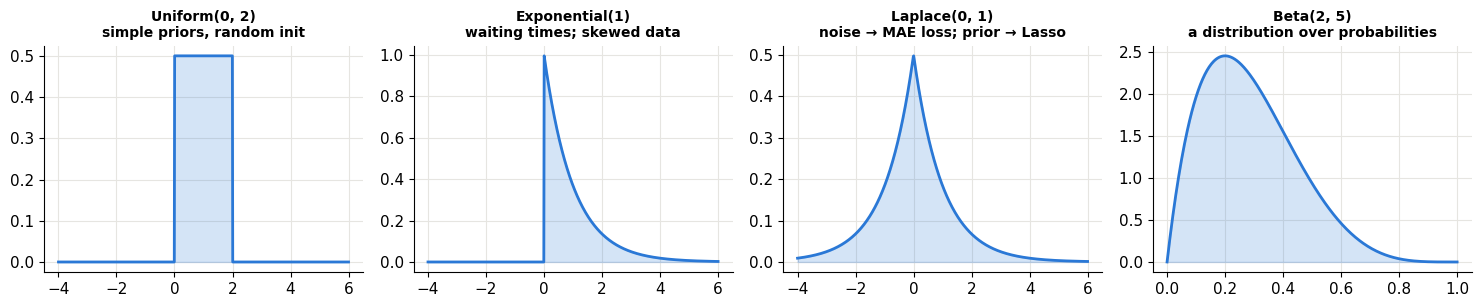

In [6]:
x = np.linspace(-4, 6, 800)
dists = [("Uniform(0, 2)", stats.uniform(0, 2), "simple priors, random init"),
         ("Exponential(1)", stats.expon(), "waiting times; skewed data"),
         ("Laplace(0, 1)", stats.laplace(), "noise → MAE loss; prior → Lasso"),
         ("Beta(2, 5)", stats.beta(2, 5), "a distribution over probabilities")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (name, d, use) in zip(axes, dists):
    xx = np.linspace(0, 1, 400) if "Beta" in name else x
    ax.plot(xx, d.pdf(xx), color=C["blue"]); ax.fill_between(xx, d.pdf(xx), color=C["blue"], alpha=0.2)
    ax.set_title(f"{name}\n{use}", fontsize=10)
fig.tight_layout(); plt.show()

---
## 4. Expectation and variance

The **expectation** (mean) is the probability-weighted average value; the **variance** measures spread around it:

$$\mathbb{E}[X] = \sum_x x\,p(x) \;\;\text{or}\;\; \int x\,p(x)\,dx, \qquad \text{Var}[X] = \mathbb{E}\big[(X - \mathbb{E}[X])^2\big] = \mathbb{E}[X^2] - \mathbb{E}[X]^2$$

The standard deviation $\sigma = \sqrt{\text{Var}[X]}$ is in the same units as $X$.

Two rules used constantly: expectation is **linear**, $\mathbb{E}[aX + bY] = a\mathbb{E}[X] + b\mathbb{E}[Y]$ (always), and $\text{Var}[aX] = a^2\,\text{Var}[X]$.

In practice we rarely know $p(x)$, so we **estimate** from samples. That's **Monte Carlo** estimation, and it's how SGD estimates gradients (notebook 03):

$$\mathbb{E}[f(X)] \approx \frac{1}{N}\sum_{i=1}^N f(x_i), \qquad x_i \sim p$$

In [7]:
samples = rng.exponential(scale=2.0, size=100_000)       # true mean 2, true variance 4
print(f"Monte Carlo mean     = {samples.mean():.4f}   (true 2)")
print(f"Monte Carlo variance = {samples.var():.4f}   (true 4)")
print(f"E[X²] − E[X]²        = {np.mean(samples**2) - samples.mean()**2:.4f}")

Monte Carlo mean     = 1.9923   (true 2)
Monte Carlo variance = 3.9979   (true 4)
E[X²] − E[X]²        = 3.9979


> 🤔 **Question: Why do statistics classes divide by $n-1$ instead of $n$ for the sample variance?**
>
> Because the sample mean $\bar x$ is computed from the same data, so the data sits slightly *closer* to $\bar x$ than to the true mean. Dividing by $n$ then systematically **underestimates** the variance; dividing by $n-1$ ("Bessel's correction") fixes the bias exactly. Let's verify by simulating many tiny samples of size 5 from a distribution with true variance 1:

In [8]:
small = rng.normal(0, 1, size=(200_000, 5))
print(f"average of var with 1/n     : {small.var(axis=1, ddof=0).mean():.4f}  ← biased (≈ (n−1)/n = 0.8)")
print(f"average of var with 1/(n−1) : {small.var(axis=1, ddof=1).mean():.4f}  ← unbiased (≈ 1)")

average of var with 1/n     : 0.8019  ← biased (≈ (n−1)/n = 0.8)
average of var with 1/(n−1) : 1.0023  ← unbiased (≈ 1)


(The MLE of the Gaussian variance uses $1/n$, as we'll derive in section 9. It's slightly biased, but the bias vanishes as $n$ grows.)

---
## 5. The central limit theorem (CLT)

Take **any** distribution with finite variance, draw $n$ samples, and compute their average. Repeat many times. The averages will be approximately **Gaussian**, centered at the true mean with variance $\sigma^2/n$, and this gets better as $n$ grows:

$$\bar X_n = \frac{1}{n}\sum_{i=1}^n X_i \;\approx\; \mathcal{N}\!\left(\mu, \frac{\sigma^2}{n}\right)$$

### 🎬 Watch a skewed distribution turn into a bell curve

The starting distribution is Exponential(1), which is very lopsided. Each frame shows 20,000 averages of $n$ samples, with the CLT's predicted Gaussian in orange.

In [9]:
ns = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 50]
fig, ax = plt.subplots(figsize=(7, 4), dpi=80)

def frame(i):
    n = ns[i]
    means = rng.exponential(1.0, size=(20_000, n)).mean(axis=1)
    ax.cla()
    ax.hist(means, bins=80, range=(0, 4), density=True, color=C["blue"], alpha=0.6)
    xx = np.linspace(0, 4, 400)
    ax.plot(xx, stats.norm.pdf(xx, 1, 1 / np.sqrt(n)), color=C["orange"], lw=2.5, label="CLT prediction N(1, 1/n)")
    ax.set(xlim=(0, 4), ylim=(0, 3.2), title=f"Averages of n = {n} exponential samples", xlabel="sample mean")
    ax.legend(loc="upper right")
    fig.tight_layout()

show_anim(animation.FuncAnimation(fig, frame, frames=len(ns), interval=700))

🎚️ **Try other starting distributions**, even a bimodal one (two separate humps) or a coin flip. The averages still become Gaussian.

In [10]:
sources = {
    "exponential (skewed)": lambda size: rng.exponential(1.0, size),
    "uniform": lambda size: rng.uniform(0, 1, size),
    "coin flip (0 or 1)": lambda size: (rng.random(size) < 0.3).astype(float),
    "bimodal (two humps)": lambda size: np.where(rng.random(size) < 0.5, rng.normal(-2, 0.4, size), rng.normal(2, 0.4, size)),
}

def plot_clt(source="bimodal (two humps)", n=1):
    draw = sources[source]
    pop = draw(200_000)
    means = draw((20_000, n)).mean(axis=1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
    ax1.hist(pop, bins=80, density=True, color=C["muted"], alpha=0.6); ax1.set_title("the original distribution")
    ax2.hist(means, bins=80, density=True, color=C["blue"], alpha=0.6)
    xx = np.linspace(means.min(), means.max(), 300)
    ax2.plot(xx, stats.norm.pdf(xx, pop.mean(), pop.std() / np.sqrt(n)), color=C["orange"], lw=2.5)
    ax2.set_title(f"averages of n = {n} samples  (orange = CLT)")
    plt.show()

interact(plot_clt, source=widgets.Dropdown(options=list(sources), value="bimodal (two humps)", description="source"),
         n=IntSlider(value=1, min=1, max=60, description="n", continuous_update=False));

> 🤔 **Question: Why should an ML person care about the CLT?**
>
> - **Noise is often Gaussian** because it's the sum of many small independent effects (that's the CLT). This justifies the Gaussian noise assumption behind MSE.
> - **Mini-batch gradients** in SGD are averages over a batch, so their noise is approximately Gaussian with variance shrinking like $1/\text{batch size}$ (notebook 03).
> - **Error bars**: the $\sigma/\sqrt n$ rule tells you how many test examples you need before a reported accuracy is trustworthy.

---
## 6. Joint, marginal and conditional distributions

With two random variables $X$ and $Y$:

- **Joint** $p(x, y)$: the probability of both together.
- **Marginal** $p(x) = \sum_y p(x, y)$: sum out the variable you don't care about.
- **Conditional** $p(y \mid x) = \dfrac{p(x, y)}{p(x)}$: zoom into the slice where $X = x$ and renormalize.
- **Product rule**: $p(x, y) = p(y \mid x)\,p(x)$.

A small discrete example: weather and whether your MARTA train is late (made-up numbers).

In [11]:
joint = pd.DataFrame([[0.08, 0.12], [0.07, 0.43], [0.05, 0.25]],
                     index=["rain", "sun", "clouds"], columns=["late", "on time"])
print("Joint p(weather, train):"); display(joint)
print("Total =", joint.to_numpy().sum())

p_weather = joint.sum(axis=1)                     # marginal: sum over train status
p_train = joint.sum(axis=0)                       # marginal: sum over weather
print("\nMarginal p(weather):", p_weather.to_dict())
print("Marginal p(train):  ", p_train.to_dict())
print("\nConditional p(train | weather) — each row now sums to 1:")
display((joint.div(p_weather, axis=0)).round(3))

Joint p(weather, train):


,late,on time
rain,0.08,0.12
sun,0.07,0.43
clouds,0.05,0.25


Total = 1.0

Marginal p(weather): {'rain': 0.2, 'sun': 0.5, 'clouds': 0.3}
Marginal p(train):   {'late': 0.2, 'on time': 0.8}

Conditional p(train | weather) — each row now sums to 1:


,late,on time
rain,0.400,0.600
sun,0.140,0.860
clouds,0.167,0.833


The train is late 40% of the time when it rains but only 14% of the time when it's sunny. Conditioning changed our belief.

**Independence**: $X$ and $Y$ are independent if $p(x, y) = p(x)\,p(y)$, equivalently $p(y \mid x) = p(y)$: learning $x$ tells you nothing about $y$.

### The same ideas with a continuous joint distribution

🎚️ Below is a 2-D Gaussian with correlation $\rho$. The **vertical line** at $x_0$ picks a slice; the right panel shows the **conditional** $p(y \mid x = x_0)$ (orange) next to the **marginal** $p(y)$ (gray). With $\rho = 0$ they coincide (independence). With strong correlation, knowing $x$ pins down $y$ much more tightly.

In [12]:
def plot_conditional(rho=0.7, x0=1.0):
    g = np.linspace(-3.5, 3.5, 200); GX, GY = np.meshgrid(g, g)
    pdf = stats.multivariate_normal([0, 0], [[1, rho], [rho, 1]]).pdf(np.dstack([GX, GY]))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1.1, 1]))
    ax1.contourf(GX, GY, pdf, levels=20, cmap="Blues")
    ax1.axvline(x0, color=C["orange"], lw=2.5)
    ax1.set(aspect="equal", xlabel="x", ylabel="y", title=f"joint p(x, y),  ρ = {rho:.2f}"); ax1.grid(False)
    yy = np.linspace(-3.5, 3.5, 300)
    ax2.plot(yy, stats.norm.pdf(yy, 0, 1), color=C["muted"], ls="--", label="marginal p(y)")
    cm, cs = rho * x0, np.sqrt(1 - rho**2)            # conditional of a standard bivariate Gaussian
    ax2.plot(yy, stats.norm.pdf(yy, cm, cs), color=C["orange"], label=f"p(y | x={x0:.1f}) = N({cm:.2f}, {cs**2:.2f})")
    ax2.fill_between(yy, stats.norm.pdf(yy, cm, cs), color=C["orange"], alpha=0.2)
    ax2.set(xlabel="y", ylim=(0, 2.2), title="slice through the joint, renormalized"); ax2.legend(loc="upper left")
    plt.show()

interact(plot_conditional, rho=FloatSlider(value=0.7, min=-0.95, max=0.95, step=0.05, description="ρ"),
         x0=FloatSlider(value=1, min=-2.5, max=2.5, step=0.1, description="x₀"));

> 🤔 **Question: If two variables have zero correlation, are they independent?**
>
> No. Correlation only measures **linear** relationships. Below, $y$ is completely determined by $x$ ($y = x^2$ plus a little noise), yet the correlation is about zero, because the relationship is a U-shape, not a line. (For jointly *Gaussian* variables, though, zero correlation *does* imply independence.)

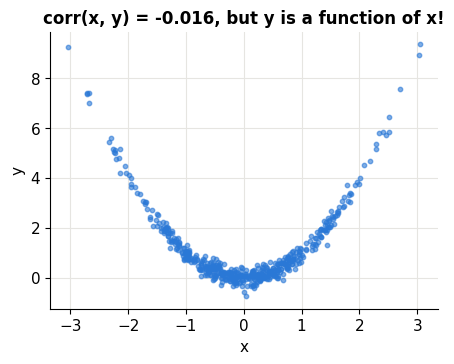

In [13]:
xs_ = rng.normal(size=500); ys_ = xs_**2 + rng.normal(0, 0.2, 500)
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.scatter(xs_, ys_, s=10, color=C["blue"], alpha=0.6)
ax.set(title=f"corr(x, y) = {np.corrcoef(xs_, ys_)[0, 1]:+.3f}, but y is a function of x!", xlabel="x", ylabel="y")
plt.show()

---
## 7. Bayes' rule

Combine the product rule both ways, $p(x, y) = p(y\mid x)p(x) = p(x \mid y)p(y)$, and you get **Bayes' rule**:

$$\underbrace{p(\theta \mid \text{data})}_{\text{posterior}} = \frac{\overbrace{p(\text{data} \mid \theta)}^{\text{likelihood}}\;\overbrace{p(\theta)}^{\text{prior}}}{\underbrace{p(\text{data})}_{\text{evidence}}}$$

It tells you how to **update a belief** when you see evidence. It's the foundation of Naive Bayes (notebook 09), MAP estimation (section 10 below), and Bayesian ML in general.

### The famous medical-test example

A disease affects **1%** of people. A test catches **99%** of sick people (sensitivity) and correctly clears **95%** of healthy people (specificity). You test positive. What's the chance you're actually sick?

Most people guess ~95%. Let's count 1,000 people:

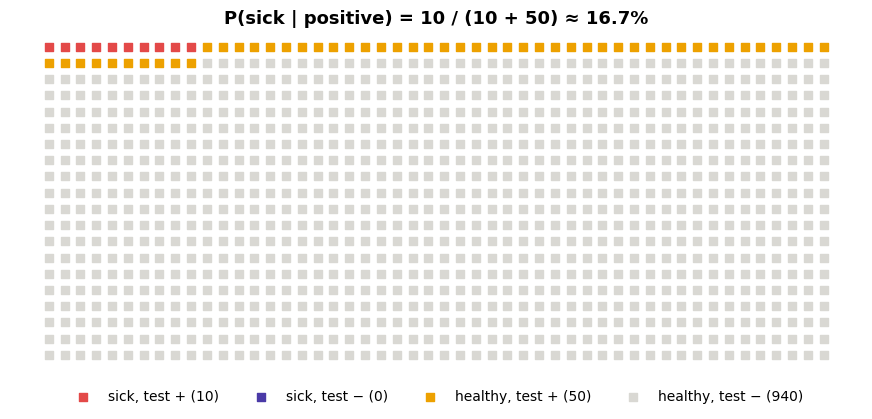

In [14]:
def bayes_grid(prevalence=0.01, sensitivity=0.99, specificity=0.95, N=1000):
    sick = int(round(prevalence * N)); healthy = N - sick
    tp = int(round(sensitivity * sick)); fn = sick - tp
    fp = int(round((1 - specificity) * healthy)); tn = healthy - fp
    groups = [(tp, C["red"], f"sick, test + ({tp})"), (fn, C["violet"], f"sick, test − ({fn})"),
              (fp, C["yellow"], f"healthy, test + ({fp})"), (tn, C["light"], f"healthy, test − ({tn})")]
    cols = 50
    fig, ax = plt.subplots(figsize=(11, 4.4))
    start = 0
    for count, col, label in groups:
        idx = np.arange(start, start + count)
        ax.scatter(idx % cols, -(idx // cols), marker="s", s=38, color=col, label=label)
        start += count
    post = sensitivity * prevalence / (sensitivity * prevalence + (1 - specificity) * (1 - prevalence))
    ax.set_title(f"P(sick | positive) = {tp} / ({tp} + {fp}) ≈ {post:.1%}", fontsize=13)
    ax.axis("off"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, fontsize=10)
    plt.show()

bayes_grid()

Only about **17%**! Among 1,000 people, 10 are sick and ~10 of them test positive, but ~50 of the 990 healthy people *also* test positive. The positives are dominated by false alarms because the disease is rare. The **prior** (base rate) matters enormously.

In Bayes'-rule form:
$$P(\text{sick} \mid +) = \frac{P(+ \mid \text{sick})\,P(\text{sick})}{P(+ \mid \text{sick})P(\text{sick}) + P(+ \mid \text{healthy})P(\text{healthy})} = \frac{0.99 \times 0.01}{0.99 \times 0.01 + 0.05 \times 0.99} \approx 0.167$$

🎚️ **Change the base rate and the test's accuracy.** How rare must the disease be before a positive result is more likely a false alarm? What happens if specificity goes to 99.9%?

In [15]:
interact(bayes_grid,
         prevalence=FloatSlider(value=0.01, min=0.001, max=0.5, step=0.001, readout_format=".3f", description="prevalence"),
         sensitivity=FloatSlider(value=0.99, min=0.5, max=1.0, step=0.01, description="sensitivity"),
         specificity=FloatSlider(value=0.95, min=0.5, max=0.999, step=0.001, readout_format=".3f", description="specificity"),
         N=widgets.fixed(1000));

> 🤔 **Question: How does this connect to ML?**
>
> It's the **class imbalance** problem you'll meet in notebook 10. A fraud detector that's "99% accurate" can still produce mostly false alarms if fraud is rare. That's why we look at **precision** (exactly the $P(\text{sick} \mid +)$ computed above) and **recall** (the sensitivity) instead of accuracy alone. Same math, different names.

---
## 8. The multivariate Gaussian and the covariance matrix

For a vector $x \in \mathbb{R}^d$, the Gaussian generalizes to

$$\mathcal{N}(x \mid \mu, \Sigma) = \frac{1}{(2\pi)^{d/2}|\Sigma|^{1/2}} \exp\!\left(-\tfrac12 (x-\mu)^\top \Sigma^{-1} (x-\mu)\right)$$

- $\mu \in \mathbb{R}^d$ is the center.
- $\Sigma \in \mathbb{R}^{d\times d}$ is the **covariance matrix**: $\Sigma_{ii}$ is the variance of feature $i$, and $\Sigma_{ij} = \text{Cov}(x_i, x_j)$. It is always **symmetric and PSD** (notebook 01!).

The contours of equal density are **ellipses**, and here linear algebra comes back: the ellipse's axes point along the **eigenvectors** of $\Sigma$, with lengths proportional to $\sqrt{\lambda_i}$. This is precisely the idea behind **PCA** (notebook 16).

🎚️ **Shape the Gaussian.** Red and orange arrows: eigenvectors of $\Sigma$ scaled by $\sqrt\lambda$. Ellipses: 1σ, 2σ, 3σ contours.

In [16]:
def cov_ellipse(mu, Sigma, nsig, num=200):
    lam, V = np.linalg.eigh(Sigma)
    t = np.linspace(0, 2 * np.pi, num)
    circ = np.vstack([np.cos(t), np.sin(t)])
    return (V @ (nsig * np.sqrt(lam)[:, None] * circ)).T + mu

def plot_mvn(sigma1=1.5, sigma2=0.8, rho=0.6):
    Sigma = np.array([[sigma1**2, rho * sigma1 * sigma2], [rho * sigma1 * sigma2, sigma2**2]])
    pts = rng.multivariate_normal([0, 0], Sigma, 600)
    lam, V = np.linalg.eigh(Sigma)
    fig, ax = plt.subplots(figsize=(5.6, 5.6))
    ax.scatter(*pts.T, s=8, color=C["blue"], alpha=0.35)
    for k in (1, 2, 3):
        ax.plot(*cov_ellipse(np.zeros(2), Sigma, k).T, color=C["ink"], lw=1.2, alpha=0.8 - 0.2 * k)
    for i, col in [(1, C["red"]), (0, C["orange"])]:
        ax.annotate("", xy=np.sqrt(lam[i]) * V[:, i], xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=3, mutation_scale=18))
    ax.set(xlim=(-5, 5), ylim=(-5, 5), aspect="equal",
           title=f"Σ = [[{Sigma[0,0]:.2f}, {Sigma[0,1]:.2f}], [{Sigma[1,0]:.2f}, {Sigma[1,1]:.2f}]]\neigenvalues λ = {lam.round(2)}")
    plt.show()

interact(plot_mvn, sigma1=FloatSlider(value=1.5, min=0.3, max=2.5, step=0.1, description="σ₁"),
         sigma2=FloatSlider(value=0.8, min=0.3, max=2.5, step=0.1, description="σ₂"),
         rho=FloatSlider(value=0.6, min=-0.95, max=0.95, step=0.05, description="ρ"));

### Linear transforms of Gaussians stay Gaussian

If $z \sim \mathcal{N}(0, I)$ and $x = Az + \mu$, then

$$x \sim \mathcal{N}(\mu,\; AA^\top)$$

So to **sample** from any Gaussian $\mathcal{N}(\mu, \Sigma)$, factor $\Sigma = LL^\top$ (the **Cholesky** decomposition) and set $x = Lz + \mu$. This exact trick reappears in the VAE (notebook 23) as the **reparameterization trick**.

In [17]:
mu = np.array([2.0, -1.0]); Sigma = np.array([[2.0, 1.2], [1.2, 1.5]])
L = np.linalg.cholesky(Sigma)                 # Σ = L Lᵀ, L lower-triangular
z = rng.normal(size=(100_000, 2))             # standard normal samples
x = z @ L.T + mu                              # transform them
print("target Σ:\n", Sigma)
print("empirical covariance of x:\n", np.cov(x.T).round(3))
print("empirical mean:", x.mean(axis=0).round(3))

target Σ:
 [[2.  1.2]
 [1.2 1.5]]
empirical covariance of x:
 [[1.997 1.198]
 [1.198 1.501]]
empirical mean: [ 2.01  -0.994]


> 🤔 **Question: What's the $(x-\mu)^\top\Sigma^{-1}(x-\mu)$ in the exponent?**
>
> It's the squared **Mahalanobis distance**: a distance that accounts for the shape of the data. A point 2 units away along the long axis of the ellipse is "normal"; the same 2 units along the short axis is unusual. It's the basis of statistical **anomaly detection** (notebook 18): points with large Mahalanobis distance are flagged.

---
## 9. Maximum likelihood estimation (MLE)

Now the main event. We have data $\mathcal{D} = \{x_1, \dots, x_n\}$ and a model $p(x \mid \theta)$ with unknown parameters. The **likelihood** is how probable the observed data is under a given $\theta$ (assuming the samples are independent and identically distributed, "i.i.d."):

$$L(\theta) = p(\mathcal{D} \mid \theta) = \prod_{i=1}^n p(x_i \mid \theta)$$

**MLE**: choose the $\theta$ that makes the data most probable, $\hat\theta_{\text{MLE}} = \arg\max_\theta L(\theta)$. In practice we maximize the **log**-likelihood, which has the same maximizer but turns the product into a sum:

$$\ell(\theta) = \log L(\theta) = \sum_{i=1}^n \log p(x_i \mid \theta)$$

### Example 1: a coin

You flip a coin $n=10$ times and see $k=7$ heads. Each flip is Bernoulli($\phi$), so

$$L(\phi) = \phi^{7}(1-\phi)^{3}, \qquad \ell(\phi) = 7\log\phi + 3\log(1-\phi)$$

Set the derivative to zero: $\frac{7}{\phi} - \frac{3}{1-\phi} = 0 \Rightarrow \hat\phi = \frac{7}{10}$. In general $\hat\phi_{\text{MLE}} = k/n$, the fraction of heads, which is reassuringly obvious.

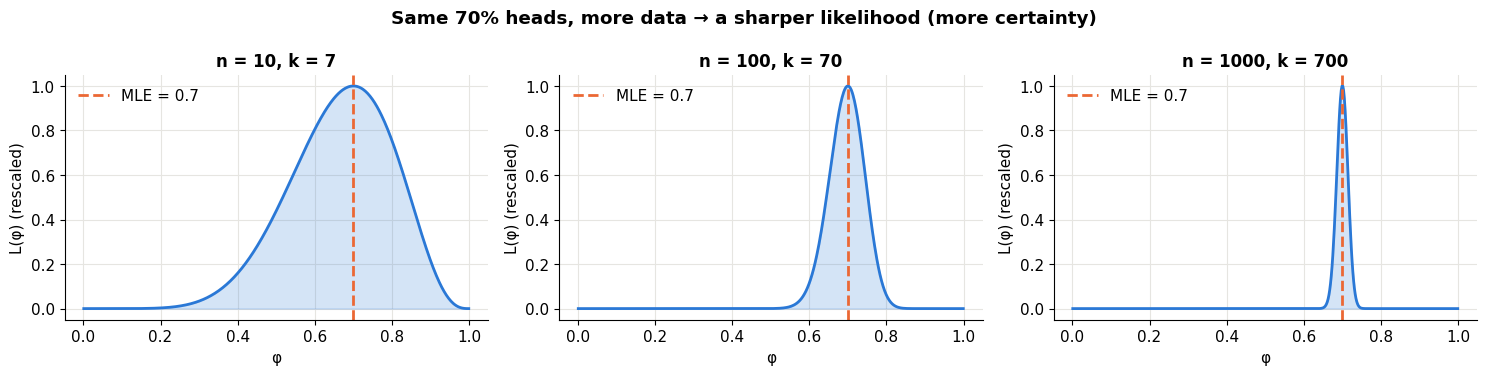

In [18]:
phi = np.linspace(0.001, 0.999, 500)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (n_, k_) in zip(axes, [(10, 7), (100, 70), (1000, 700)]):
    loglik = k_ * np.log(phi) + (n_ - k_) * np.log(1 - phi)
    lik = np.exp(loglik - loglik.max())                # rescaled so the peak = 1 (avoids underflow)
    ax.plot(phi, lik, color=C["blue"]); ax.fill_between(phi, lik, color=C["blue"], alpha=0.2)
    ax.axvline(k_ / n_, color=C["orange"], ls="--", label=f"MLE = {k_/n_}")
    ax.set(title=f"n = {n_}, k = {k_}", xlabel="φ", ylabel="L(φ) (rescaled)"); ax.legend()
fig.suptitle("Same 70% heads, more data → a sharper likelihood (more certainty)", weight="bold")
fig.tight_layout(); plt.show()

> 🤔 **Question: Why take the log? It's the same maximizer anyway.**
>
> Three practical reasons. (1) **Numerical underflow**: multiplying thousands of probabilities less than 1 gives a number too small for a computer to store. (2) Sums are easier to **differentiate** than products. (3) Sums of per-example terms are exactly what **SGD** needs (average over a mini-batch). Watch the underflow happen:

In [19]:
probs = rng.uniform(0.1, 0.9, size=2000)
print("product of 2,000 probabilities :", np.prod(probs), " ← underflowed to exactly 0!")
print("sum of their logs              :", np.sum(np.log(probs)), " ← perfectly fine")

product of 2,000 probabilities : 0.0  ← underflowed to exactly 0!
sum of their logs              : -1650.7587046039844  ← perfectly fine


### Example 2: a Gaussian (CX 4240 Lecture 3)

Data $x_1..x_n \sim \mathcal{N}(\mu, \sigma^2)$. The log-likelihood is

$$\ell(\mu, \sigma^2) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^n (x_i - \mu)^2$$

- $\partial \ell/\partial\mu = \frac{1}{\sigma^2}\sum_i (x_i - \mu) = 0 \;\Rightarrow\; \hat\mu = \frac1n\sum_i x_i$ (the sample mean)
- $\partial \ell/\partial\sigma^2 = -\frac{n}{2\sigma^2} + \frac{1}{2\sigma^4}\sum_i (x_i-\mu)^2 = 0 \;\Rightarrow\; \hat\sigma^2 = \frac1n\sum_i (x_i - \hat\mu)^2$

🎚️ **You be the MLE.** Drag $\mu$ and $\sigma$ to make the 15 data points as probable as possible. The orange stems are each point's density $p(x_i \mid \mu,\sigma)$; the log-likelihood adds up their logs. Notice the tradeoff with $\sigma$: too narrow and outer points get almost zero density, too wide and every point's density is low.

In [20]:
data = rng.normal(3.0, 1.2, size=15)
mle_mu, mle_sigma = data.mean(), data.std()          # np.std uses 1/n by default = the MLE
best_ll = stats.norm.logpdf(data, mle_mu, mle_sigma).sum()

def plot_mle(mu=1.0, sigma=2.0):
    xx = np.linspace(-2, 8, 400)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(xx, stats.norm.pdf(xx, mu, sigma), color=C["blue"], label="your Gaussian")
    dens = stats.norm.pdf(data, mu, sigma)
    ax.vlines(data, 0, dens, color=C["orange"], lw=2)
    ax.plot(data, dens, "o", color=C["orange"], label="density at each data point")
    ax.plot(data, np.zeros_like(data), "|", color=C["ink"], markersize=14)
    ll = stats.norm.logpdf(data, mu, sigma).sum()
    ax.set(ylim=(0, 0.6), xlabel="x", title=f"log-likelihood = {ll:.2f}    (best possible: {best_ll:.2f})")
    ax.legend(loc="upper right"); plt.show()

interact(plot_mle, mu=FloatSlider(value=1, min=-1, max=7, step=0.05, description="μ"),
         sigma=FloatSlider(value=2, min=0.3, max=4, step=0.05, description="σ"));

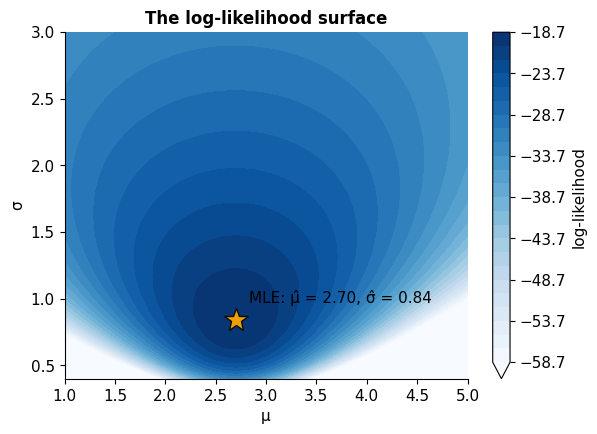

Data were generated with μ = 3.0, σ = 1.2. Fifteen points is very little data, so the estimates can be
noticeably off. Change size=15 to size=1000 in the cell above and they'll land much closer.


In [21]:
M, S = np.meshgrid(np.linspace(1, 5, 200), np.linspace(0.4, 3, 200))
LL = stats.norm.logpdf(data[None, None, :], M[..., None], S[..., None]).sum(-1)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
cs = ax.contourf(M, S, LL, levels=np.linspace(LL.max() - 40, LL.max(), 25), cmap="Blues", extend="min")
ax.plot(mle_mu, mle_sigma, "*", color=C["yellow"], markersize=18, markeredgecolor=C["ink"])
ax.annotate(f"MLE: μ̂ = {mle_mu:.2f}, σ̂ = {mle_sigma:.2f}", (mle_mu, mle_sigma), xytext=(10, 12), textcoords="offset points")
ax.set(xlabel="μ", ylabel="σ", title="The log-likelihood surface"); ax.grid(False)
plt.colorbar(cs, ax=ax, label="log-likelihood"); plt.show()
print("Data were generated with μ = 3.0, σ = 1.2. Fifteen points is very little data, so the estimates can be\n"
      "noticeably off. Change size=15 to size=1000 in the cell above and they'll land much closer.")

---
## 10. MAP estimation: adding prior beliefs

MLE trusts the data completely. With very little data that's dangerous: flip a coin 3 times, get 3 heads, and MLE says $\hat\phi = 1$, so "this coin can never land tails". A **prior** $p(\theta)$ encodes what you believed before seeing data, and Bayes' rule combines them:

$$p(\theta \mid \mathcal{D}) \propto p(\mathcal{D} \mid \theta)\,p(\theta)$$

**MAP** (maximum a posteriori) picks the peak of the posterior:

$$\hat\theta_{\text{MAP}} = \arg\max_\theta \Big[\underbrace{\log p(\mathcal{D}\mid\theta)}_{\text{log-likelihood}} + \underbrace{\log p(\theta)}_{\text{log-prior}}\Big]$$

### Beta–Bernoulli: a prior over a coin's bias

For a coin, a convenient prior is $\text{Beta}(\alpha, \beta)$, which acts like **$\alpha-1$ imaginary heads and $\beta-1$ imaginary tails** seen in advance. After $k$ heads in $n$ flips, the posterior is again a Beta:

$$p(\phi \mid \mathcal{D}) = \text{Beta}(\alpha + k,\; \beta + n - k), \qquad \hat\phi_{\text{MAP}} = \frac{k + \alpha - 1}{n + \alpha + \beta - 2}$$

### 🎬 Watch beliefs update, one flip at a time

True bias 0.7, prior Beta(5, 5) (a mild belief that the coin is fair). Each frame adds one flip. Watch the posterior (blue) move from the prior toward the truth and get **narrower** (more certain) as evidence piles up, while MLE (orange) jumps around early on.

In [22]:
seq = (rng.random(60) < 0.7).astype(int)
a0, b0 = 5, 5
phi = np.linspace(0.001, 0.999, 400)
fig, ax = plt.subplots(figsize=(8, 4), dpi=80)

def frame(n_):
    k_ = seq[:n_].sum()
    ax.cla()
    ax.plot(phi, stats.beta.pdf(phi, a0, b0), color=C["muted"], ls="--", label="prior Beta(5, 5)")
    post = stats.beta.pdf(phi, a0 + k_, b0 + n_ - k_)
    ax.plot(phi, post, color=C["blue"], label="posterior"); ax.fill_between(phi, post, color=C["blue"], alpha=0.2)
    ax.axvline(0.7, color=C["ink"], lw=1, label="truth 0.7")
    if n_ > 0:
        ax.axvline(k_ / n_, color=C["orange"], ls=":", lw=2, label=f"MLE = {k_/n_:.2f}")
    ax.axvline((k_ + a0 - 1) / (n_ + a0 + b0 - 2), color=C["blue"], ls="-.", lw=2,
               label=f"MAP = {(k_ + a0 - 1) / (n_ + a0 + b0 - 2):.2f}")
    ax.set(ylim=(0, 8), xlim=(0, 1), xlabel="φ (probability of heads)", title=f"after {n_} flips: {k_} heads")
    ax.legend(loc="upper left", fontsize=9)
    fig.tight_layout()

show_anim(animation.FuncAnimation(fig, frame, frames=len(seq) + 1, interval=150))

🎚️ **Prior strength vs. data.** A stronger prior ($\alpha = \beta$ large) resists the data longer; more flips eventually overwhelm any reasonable prior.

In [23]:
def plot_prior(prior_strength=5, n_flips=5):
    k_ = seq[:n_flips].sum(); a = b = prior_strength
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(phi, stats.beta.pdf(phi, a, b), color=C["muted"], ls="--", label=f"prior Beta({a}, {b})")
    lik = np.exp(k_ * np.log(phi) + (n_flips - k_) * np.log(1 - phi)); lik /= lik.sum() * (phi[1] - phi[0])
    ax.plot(phi, lik, color=C["orange"], label="likelihood (normalized)")
    ax.plot(phi, stats.beta.pdf(phi, a + k_, b + n_flips - k_), color=C["blue"], lw=2.5, label="posterior")
    ax.set(xlabel="φ", title=f"{k_} heads in {n_flips} flips → MLE {k_/n_flips:.2f}, "
                             f"MAP {(k_ + a - 1)/(n_flips + a + b - 2):.2f}")
    ax.legend(loc="upper left"); plt.show()

interact(plot_prior, prior_strength=IntSlider(value=5, min=1, max=50, description="α = β"),
         n_flips=IntSlider(value=5, min=1, max=60, description="# flips"));

### The punchline: a Gaussian prior *is* L2 regularization

Put a Gaussian prior on each weight of a model, $\theta_j \sim \mathcal{N}(0, \tau^2)$. Then

$$-\log p(\theta) = \frac{1}{2\tau^2}\sum_j \theta_j^2 + \text{const} = \lambda\|\theta\|_2^2 + \text{const}, \qquad \lambda = \frac{1}{2\tau^2}$$

So **MAP = minimize (loss + $\lambda\|\theta\|^2$)**. That's **Ridge regression** and **weight decay** in neural networks. A Laplace prior gives $\lambda\|\theta\|_1$, which is **Lasso**. Regularization isn't a hack: it's a prior belief that weights should be small. (Notebook 07 explores this in depth.)

---
## 11. From likelihoods to loss functions

Now we can see where every common loss comes from. The recipe:

1. Pick a probability model for the target given the input.
2. Write the negative log-likelihood (NLL).
3. Drop the constants. What's left is the loss.

### Gaussian noise → mean squared error (the apartment example)

CX 4240 models rent as a linear function plus Gaussian noise: $y_i = \theta^\top x_i + \epsilon_i$, $\epsilon_i \sim \mathcal{N}(0, \sigma^2)$. Equivalently $p(y_i \mid x_i, \theta) = \mathcal{N}(y_i \mid \theta^\top x_i, \sigma^2)$. The NLL is

$$-\ell(\theta) = \frac{n}{2}\log(2\pi\sigma^2) + \frac{1}{2\sigma^2}\sum_{i=1}^n (y_i - \theta^\top x_i)^2$$

The first term doesn't depend on $\theta$, and $\frac{1}{2\sigma^2}$ is just a positive scale. So **maximizing the Gaussian likelihood is exactly minimizing the sum of squared errors.** That's where the squared error in notebook 00 came from.

### The full table

| Target type | Probability model | Negative log-likelihood = loss | Used in |
|---|---|---|---|
| real number | Gaussian: $\mathcal{N}(y \mid f(x), \sigma^2)$ | $(y - f(x))^2$ → **MSE** | linear regression (05), neural net regression |
| real number, outliers | Laplace: $\propto e^{-\lvert y - f(x)\rvert/b}$ | $\lvert y - f(x) \rvert$ → **MAE** | robust regression |
| binary label $y\in\{0,1\}$ | Bernoulli: $p = \sigma(f(x))$ | $-[y\log p + (1-y)\log(1-p)]$ → **binary cross-entropy** | logistic regression (08) |
| one of $K$ classes | Categorical: $p = \text{softmax}(f(x))$ | $-\log p_{y}$ → **cross-entropy** | multiclass, CNNs (21), GPT (25) |

### See the difference: Gaussian (MSE) vs. Laplace (MAE) with outliers

The Laplace distribution has heavier tails, so it isn't "surprised" by occasional huge errors, and the MAE fit ignores outliers that drag the MSE fit away.

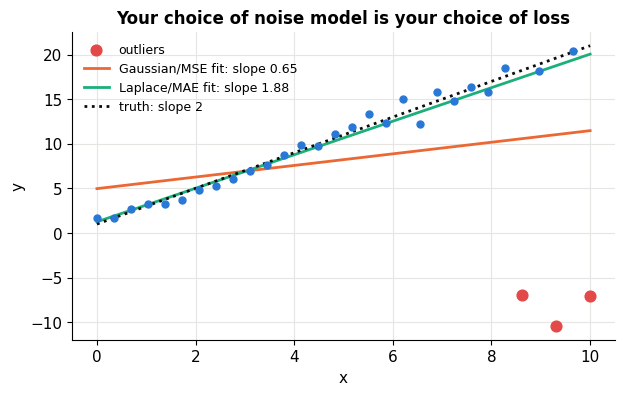

In [24]:
from scipy.optimize import minimize

xo = np.linspace(0, 10, 30); yo = 2 * xo + 1 + rng.normal(0, 1, 30)
yo[[25, 27, 29]] -= [25, 30, 28]                       # three badly corrupted points
Xo = np.column_stack([np.ones_like(xo), xo])

theta_mse = np.linalg.lstsq(Xo, yo, rcond=None)[0]
theta_mae = minimize(lambda t: np.abs(yo - Xo @ t).sum(), theta_mse, method="Nelder-Mead").x

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(xo, yo, color=C["blue"], s=25, zorder=3)
ax.scatter(xo[[25, 27, 29]], yo[[25, 27, 29]], color=C["red"], s=60, zorder=4, label="outliers")
ax.plot(xo, Xo @ theta_mse, color=C["orange"], label=f"Gaussian/MSE fit: slope {theta_mse[1]:.2f}")
ax.plot(xo, Xo @ theta_mae, color=C["aqua"], label=f"Laplace/MAE fit: slope {theta_mae[1]:.2f}")
ax.plot(xo, 2 * xo + 1, color=C["ink"], ls=":", label="truth: slope 2")
ax.set(xlabel="x", ylabel="y", title="Your choice of noise model is your choice of loss"); ax.legend(fontsize=9)
plt.show()

> 🤔 **Question: So should I always use MAE to be safe?**
>
> Not necessarily. If the noise really is Gaussian, MSE is statistically more efficient (it uses the data better) and it's smooth, which makes optimization easier. MAE's kink at 0 makes gradients jump. A popular compromise is the **Huber loss**: squared for small errors, absolute for large ones. The real lesson is that a loss function *encodes an assumption about your noise*, so choose it on purpose.

---
## 12. Entropy, cross-entropy and KL divergence

One more set of tools that every classification model and every LLM uses.

- **Entropy** $H(p) = -\sum_x p(x)\log p(x)$: the average "surprise" of a distribution. High when outcomes are spread out, zero when one outcome is certain.
- **Cross-entropy** $H(p, q) = -\sum_x p(x)\log q(x)$: the average surprise if reality follows $p$ but you *believe* $q$.
- **KL divergence** $D_{\text{KL}}(p\,\|\,q) = \sum_x p(x)\log\frac{p(x)}{q(x)} = H(p,q) - H(p) \ge 0$: the *extra* surprise from using the wrong distribution. It's zero only when $q = p$.

Since $H(p)$ doesn't depend on the model, **minimizing cross-entropy = minimizing KL = maximum likelihood**. It's the same thing viewed three ways.

🎚️ The true next-word distribution is $p$ (gray). Your model's distribution is $q$ (blue), controlled by a "temperature" that makes it sharper or flatter, and a slider that shifts its preferences. Can you drive the KL to 0?

In [25]:
vocab = ["the", "a", "cat", "dog", "ran", "sat"]
p_true = np.array([0.35, 0.2, 0.15, 0.12, 0.1, 0.08])
base_logits = np.log(p_true)

def plot_kl(temperature=1.0, shift=0.0):
    logits = base_logits / temperature + shift * np.array([-1, -0.6, 0, 0.4, 0.8, 1.2])
    q = np.exp(logits - logits.max()); q /= q.sum()
    H = -np.sum(p_true * np.log(p_true)); CE = -np.sum(p_true * np.log(q)); KL = CE - H
    fig, ax = plt.subplots(figsize=(8, 3.6))
    w = 0.38; idx = np.arange(len(vocab))
    ax.bar(idx - w / 2, p_true, w, color=C["muted"], label="p (truth)")
    ax.bar(idx + w / 2, q, w, color=C["blue"], label="q (model)")
    ax.set_xticks(idx, vocab); ax.set_ylim(0, 0.8)
    ax.set_title(f"H(p) = {H:.3f}    cross-entropy H(p,q) = {CE:.3f}    KL(p‖q) = {KL:.3f}")
    ax.legend(); plt.show()

interact(plot_kl, temperature=FloatSlider(value=1.0, min=0.2, max=4, step=0.05, description="temperature"),
         shift=FloatSlider(value=0.0, min=-2, max=2, step=0.05, description="shift"));

> 🤔 **Question: Is "temperature" the same temperature as in ChatGPT's settings?**
>
> Yes, exactly. An LLM produces logits, and dividing them by a temperature before the softmax makes sampling more random (high temperature) or more deterministic (low temperature). Notebook 25 uses it to sample text from our mini-GPT. KL divergence also shows up in VAEs (23) and as the "don't drift too far from the original model" penalty in RLHF (26).

---
## 13. Summary

| Idea | One-line takeaway | Where it comes back |
|---|---|---|
| Distributions | Bernoulli, Categorical, Gaussian are the workhorses | logistic regression, softmax, regression |
| Densities | probabilities are areas; densities can exceed 1 | everywhere continuous |
| LLN & CLT | averages converge, and their noise is Gaussian with variance σ²/n | SGD (03), evaluation |
| Conditionals & Bayes | update beliefs with evidence; base rates matter | Naive Bayes (09), precision/recall (10) |
| Multivariate Gaussian | covariance = ellipse = eigenvectors | GMM (15), PCA (16), anomaly detection (18) |
| MLE | maximize $\sum \log p(x_i\mid\theta)$ | every model's training |
| MAP | MLE + log-prior; Gaussian prior = L2 | Ridge/Lasso (07), weight decay |
| NLL = loss | Gaussian → MSE, Bernoulli → BCE, Categorical → CE | 05, 08, 19, 25 |
| KL / cross-entropy | minimizing CE = minimizing KL = MLE | classification, VAE (23), RLHF (26) |

### ✏️ Exercises

1. In the Bayes grid, a patient tests positive and then takes a **second, independent** test that is also positive. Use the first posterior (≈ 0.167) as the new prior. What's the new probability of being sick?
2. Derive the MLE of the rate $\lambda$ for exponential data $p(x\mid\lambda) = \lambda e^{-\lambda x}$. Check it numerically on `rng.exponential(scale=2, size=1000)` (note scale $= 1/\lambda$).
3. Show that with a Beta(1, 1) prior (uniform), MAP equals MLE. Why does that make sense?
4. Starting from the Bernoulli likelihood with $p = \sigma(\theta^\top x)$, write out the negative log-likelihood for $n$ examples. You've just derived logistic regression's loss (notebook 08).
5. In the outlier demo, add more outliers. At what point does the MAE fit also break down?
6. Compute $D_{\text{KL}}(p\|q)$ and $D_{\text{KL}}(q\|p)$ for two different distributions. Are they equal? (KL is *not* symmetric, so it isn't a true distance.)

### References

- CX 4240 Lecture 3 (Probability & Statistics Revisit) and Lectures 4 and 6 (Gaussian likelihood → least squares).
- C. Bishop, *Pattern Recognition and Machine Learning*, Chapter 2 (cited in CX 4240).
- K. Murphy, *Probabilistic Machine Learning: An Introduction*, Chapters 2–4.
- 3Blue1Brown, *Bayes theorem, the geometry of changing beliefs* and *But what is the Central Limit Theorem?*

**Next → [03 · Optimization](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/03_optimization.ipynb)**